Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.
Executando redes profundas em: cpu

--- COMPARAÇÃO GERAL DOS MODELOS NO TESTE (1 PASSO À FRENTE) ---


Modelo / Estratégia,RMSE (m³/d),MAE (m³/d),R²
1. Físico: Arps Exponencial,93.71,77.47,0.049
2. Físico: Arps Hiperbólico,94.61,76.45,0.03
3. Baseline Linear: Ridge,73.71,56.35,0.411
4. ML Clássico: XGBoost,61.88,43.78,0.585
5. Híbrido: Arps + Resíduo XGBoost,125.89,100.2,-0.717
6. Deep Learning: LSTM,85.26,60.14,0.212
7. Deep Learning: TCN,94.58,71.44,0.031
8. Híbrido DL: Arps + Resíduo LSTM,98.66,77.26,-0.055
9. Ref. Otimista: XGBoost (Split Aleatório),119.27,60.65,0.636


Horizonte (dias),Arps Hiperbólico,XGBoost (Recursivo),LSTM (Recursiva),TCN (Recursiva)
1,68.81979743318995,47.431205501556406,46.69703023910522,70.97426872253418
7,84.05114225491442,77.34732954891867,114.13684622041495,155.19029650035068
15,99.2653261683974,89.35389975659292,125.47494593400171,151.67999508075684
30,98.67892702047574,88.13091081631407,117.08539381847012,136.21743660810822
45,98.79656407717486,90.4261709935278,115.06290648092383,140.9405974665614
60,102.44058713419675,99.41385615345034,116.83280844841906,112.75730590108213


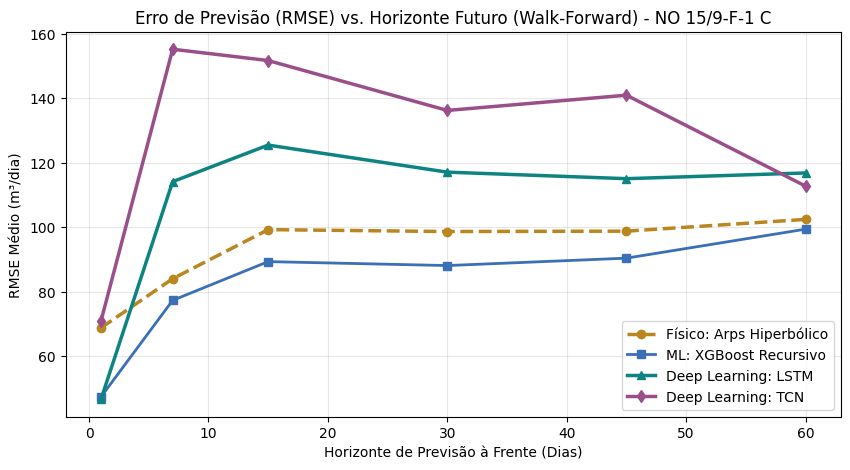

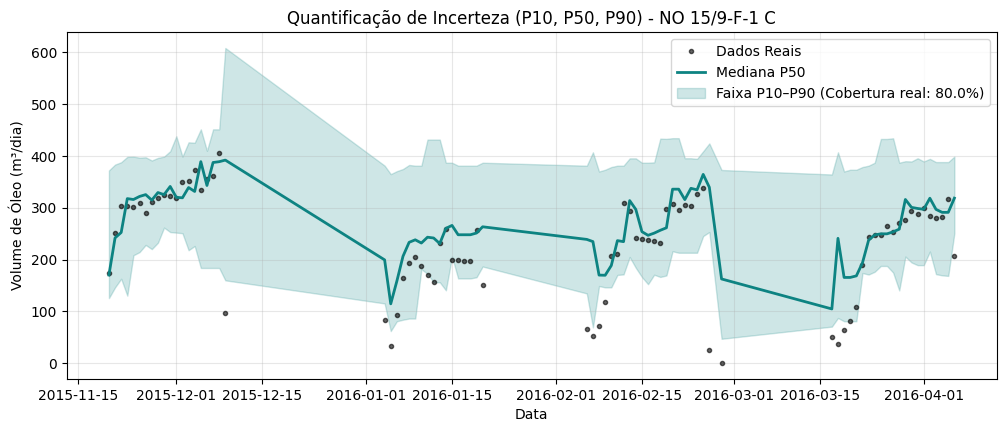

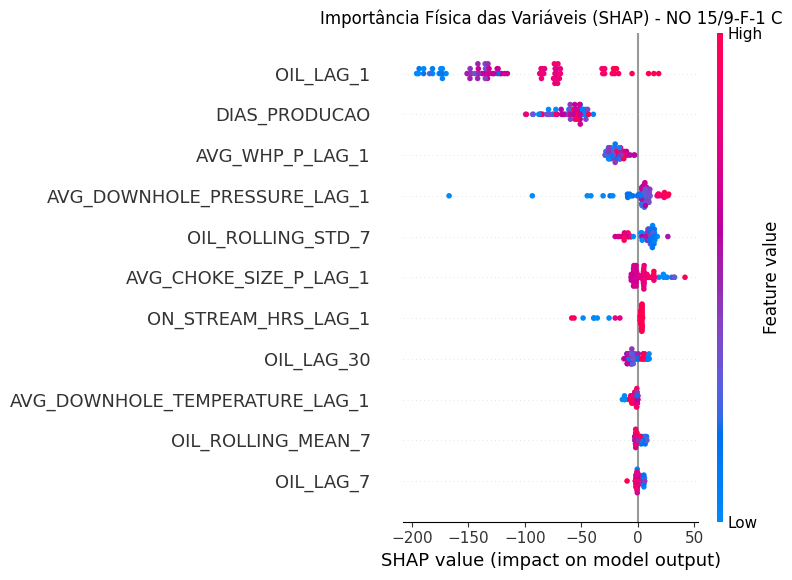


--- GENERALIZAÇÃO MULTI-POÇO (VOLVE) ---


Poço,Dias Totais,RMSE Arps Hyp (m³/d),RMSE XGBoost (m³/d)
NO 15/9-F-1 C,400,94.61,61.88
NO 15/9-F-11 H,1093,595.96,133.66
NO 15/9-F-12 H,2806,182.8,73.62
NO 15/9-F-14 H,2693,189.73,153.56
NO 15/9-F-15 D,737,34.14,48.2


--- COMPARAÇÃO DOS MODELOS HÍBRIDOS (1 PASSO À FRENTE) ---


Modelo,RMSE (m³/d),MAE (m³/d),R²
1. Físico Puro: Arps Hiperbólico,94.61,76.45,0.03
2. ML Puro: XGBoost,61.88,43.78,0.585
3. Híbrido Aditivo (Arps + Resíduo Dinâmico),72.27,52.01,0.434
4. Híbrido Multiplicativo (Arps × Eficiência),81.53,65.47,0.28
5. Híbrido Physics-Aware (XGBoost + Curva Arps),85.81,73.74,0.202


Horizonte (dias),Arps Hiperbólico,XGBoost Puro,Híbrido Aditivo,Híbrido Multiplicativo
1,68.81979743318995,47.431205501556406,48.15436182634196,54.59245317084576
7,84.05114225491442,77.34732954891867,85.10226891305007,87.71442365259242
15,99.2653261683974,89.35389975659292,96.01650724167918,97.82259438822543
30,98.67892702047574,88.13091081631407,96.10585712014871,97.55400168739376
45,98.79656407717486,90.4261709935278,96.41440849599212,97.17076589377689
60,102.44058713419675,99.41385615345034,102.53806885824187,104.08093082121582


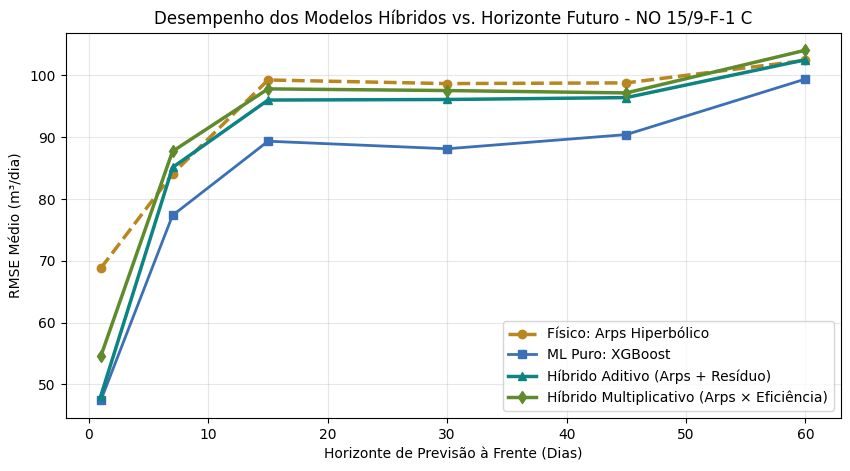

In [0]:
# ==============================================================================
# ==============================================================================
# 0. INSTALAÇÃO E IMPORTAÇÕES
# ==============================================================================
%pip install -q openpyxl xgboost tslearn shap torch

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.optimize import curve_fit
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMinMax

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Garantir reprodutibilidade
np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executando redes profundas em: {device}")

# ==============================================================================
# 1. CARREGAMENTO E PREPARAÇÃO DOS DADOS DE VOLVE
# ==============================================================================
caminho_arquivo = "/Volumes/equinor_asa_volve_data_village/public/volve/Production_data/Volve production data.xlsx"
df = pd.read_excel(caminho_arquivo, sheet_name="Daily Production Data")
df['DATEPRD'] = pd.to_datetime(df['DATEPRD'])

cols_operacionais = [
    'ON_STREAM_HRS',
    'AVG_DOWNHOLE_PRESSURE',
    'AVG_DOWNHOLE_TEMPERATURE',
    'AVG_WHP_P',
    'AVG_CHOKE_SIZE_P'
]
cols_operacionais = [c for c in cols_operacionais if c in df.columns]

def preparar_poco(df_raw, codigo_poco):
    d = df_raw[(df_raw['WELL_BORE_CODE'] == codigo_poco) & (df_raw['BORE_OIL_VOL'] > 0)].copy()
    d = d.sort_values('DATEPRD').reset_index(drop=True)
    d['DIAS_PRODUCAO'] = (d['DATEPRD'] - d['DATEPRD'].min()).dt.days
    
    # Lags estritamente passados (sem vazamento de dados)
    d['OIL_LAG_1'] = d['BORE_OIL_VOL'].shift(1)
    d['OIL_LAG_7'] = d['BORE_OIL_VOL'].shift(7)
    d['OIL_LAG_30'] = d['BORE_OIL_VOL'].shift(30)
    d['OIL_ROLLING_MEAN_7'] = d['BORE_OIL_VOL'].shift(1).rolling(window=7).mean()
    d['OIL_ROLLING_STD_7'] = d['BORE_OIL_VOL'].shift(1).rolling(window=7).std()
    
    for col in cols_operacionais:
        d[f'{col}_LAG_1'] = d[col].shift(1)
        
    d = d.dropna(subset=['OIL_LAG_30', 'OIL_ROLLING_STD_7']).ffill().bfill().reset_index(drop=True)
    return d

poco_alvo = 'NO 15/9-F-1 C'
df_ml = preparar_poco(df, poco_alvo)

# ==============================================================================
# 2. MODELOS FÍSICOS DE ARPS (AJUSTADOS APENAS NOS 80% DE TREINO)
# ==============================================================================
def arps_exponential(t, qi, D):
    return qi * np.exp(-D * t)

def arps_hyperbolic(t, qi, D, b):
    return qi / np.power(1.0 + b * D * t, 1.0 / b)

split_index = int(len(df_ml) * 0.8)
train_data = df_ml.iloc[:split_index].copy()
test_data = df_ml.iloc[split_index:].copy()

t_train, q_train = train_data['DIAS_PRODUCAO'].values, train_data['BORE_OIL_VOL'].values
t_test = test_data['DIAS_PRODUCAO'].values

popt_exp, _ = curve_fit(arps_exponential, t_train, q_train, p0=[q_train[0], 0.002], bounds=(0, [np.inf, 1.0]))
train_data['ARPS_EXP'] = arps_exponential(t_train, *popt_exp)
test_data['ARPS_EXP'] = arps_exponential(t_test, *popt_exp)

popt_hyp, _ = curve_fit(arps_hyperbolic, t_train, q_train, p0=[q_train[0], 0.002, 0.5], bounds=(0, [np.inf, 1.0, 1.0]))
train_data['ARPS_HYP'] = arps_hyperbolic(t_train, *popt_hyp)
test_data['ARPS_HYP'] = arps_hyperbolic(t_test, *popt_hyp)

# ==============================================================================
# 3. BASELINES CLÁSSICOS E HÍBRIDO CORRIGIDO (SEM EXTRAPOLAÇÃO TEMPORAL NAS ÁRVORES)
# ==============================================================================
features_ml = ['DIAS_PRODUCAO', 'OIL_LAG_1', 'OIL_LAG_7', 'OIL_LAG_30', 'OIL_ROLLING_MEAN_7', 'OIL_ROLLING_STD_7'] + \
              [f'{c}_LAG_1' for c in cols_operacionais]

# Para o modelo híbrido, removemos DIAS_PRODUCAO para que o ML aprenda apenas o desvio operacional e não extrapole tempo
features_residuo = [f for f in features_ml if f != 'DIAS_PRODUCAO']

X_train, y_train = train_data[features_ml], train_data['BORE_OIL_VOL']
X_test, y_test = test_data[features_ml], test_data['BORE_OIL_VOL']

# 3.1 Baseline Linear (Ridge)
ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train, y_train)
pred_ridge = ridge_model.predict(X_test)

# 3.2 XGBoost Puro
xgb_model = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)

# 3.3 Híbrido Corrigido (Arps Hiperbólico + Resíduo XGBoost sem DIAS_PRODUCAO)
y_train_res = y_train - train_data['ARPS_HYP']
model_res = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(train_data[features_residuo], y_train_res)
pred_hibrido_xgb = test_data['ARPS_HYP'].values + model_res.predict(test_data[features_residuo])

# 3.4 Divisão Aleatória (para demonstrar o otimismo artificial)
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(df_ml[features_ml], df_ml['BORE_OIL_VOL'], test_size=0.2, random_state=42)
pred_xgb_rand = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_tr_r, y_tr_r).predict(X_te_r)

# ==============================================================================
# 4. DEEP LEARNING: ARQUITETURAS LSTM E TCN (PYTORCH)
# ==============================================================================
SEQ_LEN = 14  # Janela histórica de 14 dias de entrada para as redes profundas

# Selecionar features para sequências 3D (vazão + variáveis operacionais)
seq_cols = ['BORE_OIL_VOL'] + cols_operacionais
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# Ajustar escalonadores APENAS no treino
scaled_train = scaler_X.fit_transform(train_data[seq_cols])
scaled_test = scaler_X.transform(test_data[seq_cols])

y_train_sc = scaler_y.fit_transform(train_data[['BORE_OIL_VOL']])
y_test_sc = scaler_y.transform(test_data[['BORE_OIL_VOL']])

def criar_sequencias(X_arr, y_arr, seq_len):
    Xs, ys = [], []
    for i in range(seq_len, len(X_arr)):
        Xs.append(X_arr[i-seq_len:i])
        ys.append(y_arr[i])
    return np.array(Xs), np.array(ys)

X_seq_tr, y_seq_tr = criar_sequencias(scaled_train, y_train_sc, SEQ_LEN)
# Para testar todos os dias de test_data, concatenamos os últimos SEQ_LEN dias do treino no início do teste
scaled_test_ctx = np.vstack([scaled_train[-SEQ_LEN:], scaled_test])
y_test_ctx = np.vstack([y_train_sc[-SEQ_LEN:], y_test_sc])
X_seq_te, y_seq_te = criar_sequencias(scaled_test_ctx, y_test_ctx, SEQ_LEN)

train_loader = DataLoader(TensorDataset(torch.tensor(X_seq_tr, dtype=torch.float32),
                                        torch.tensor(y_seq_tr, dtype=torch.float32)), batch_size=32, shuffle=True)

# 4.1 Definição da LSTM
class LSTMForecaster(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# 4.2 Definição da TCN (Temporal Convolutional Network com convoluções causais dilatadas)
class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, padding=self.pad, dilation=dilation)
    def forward(self, x):
        out = self.conv(x)
        return out[:, :, :-self.pad] if self.pad > 0 else out

class TCNForecaster(nn.Module):
    def __init__(self, input_dim, channels=32, kernel_size=3):
        super().__init__()
        self.net = nn.Sequential(
            CausalConv1d(input_dim, channels, kernel_size, dilation=1),
            nn.ReLU(),
            CausalConv1d(channels, channels, kernel_size, dilation=2),
            nn.ReLU(),
            CausalConv1d(channels, channels, kernel_size, dilation=4),
            nn.ReLU()
        )
        self.fc = nn.Linear(channels, 1)
    def forward(self, x):
        # x: (batch, seq_len, features) -> (batch, features, seq_len)
        x = x.transpose(1, 2)
        out = self.net(x)
        return self.fc(out[:, :, -1])

def treinar_dl(modelo, loader, epochs=80, lr=1e-3):
    modelo = modelo.to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    modelo.train()
    for _ in range(epochs):
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            loss = loss_fn(modelo(bx), by)
            loss.backward()
            opt.step()
    return modelo

lstm_model = treinar_dl(LSTMForecaster(len(seq_cols)), train_loader, epochs=80)
tcn_model = treinar_dl(TCNForecaster(len(seq_cols)), train_loader, epochs=80)

def prever_dl(modelo, X_arr):
    modelo.eval()
    with torch.no_grad():
        preds_sc = modelo(torch.tensor(X_arr, dtype=torch.float32).to(device)).cpu().numpy()
    return scaler_y.inverse_transform(preds_sc).ravel()

pred_lstm = prever_dl(lstm_model, X_seq_te)
pred_tcn = prever_dl(tcn_model, X_seq_te)

# 4.3 Híbrido Deep Learning (Arps Hiperbólico + Resíduo LSTM)
res_tr_sc = scaler_y.fit_transform((train_data['BORE_OIL_VOL'] - train_data['ARPS_HYP']).values.reshape(-1, 1))
X_res_tr, y_res_tr = criar_sequencias(scaled_train, res_tr_sc, SEQ_LEN)
res_loader = DataLoader(TensorDataset(torch.tensor(X_res_tr, dtype=torch.float32),
                                      torch.tensor(y_res_tr, dtype=torch.float32)), batch_size=32, shuffle=True)
lstm_res_model = treinar_dl(LSTMForecaster(len(seq_cols)), res_loader, epochs=80)
pred_hibrido_lstm = test_data['ARPS_HYP'].values + prever_dl(lstm_res_model, X_seq_te)

# ==============================================================================
# 5. TABELA CONSOLIDADA DE RESULTADOS (1 PASSO À FRENTE)
# ==============================================================================
def avaliar(y_true, y_pred, nome):
    return {
        'Modelo / Estratégia': nome,
        'RMSE (m³/d)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        'MAE (m³/d)': round(mean_absolute_error(y_true, y_pred), 2),
        'R²': round(r2_score(y_true, y_pred), 3)
    }

tabela_final = pd.DataFrame([
    avaliar(y_test, test_data['ARPS_EXP'], '1. Físico: Arps Exponencial'),
    avaliar(y_test, test_data['ARPS_HYP'], '2. Físico: Arps Hiperbólico'),
    avaliar(y_test, pred_ridge, '3. Baseline Linear: Ridge'),
    avaliar(y_test, pred_xgb, '4. ML Clássico: XGBoost'),
    avaliar(y_test, pred_hibrido_xgb, '5. Híbrido: Arps + Resíduo XGBoost'),
    avaliar(y_test, pred_lstm, '6. Deep Learning: LSTM'),
    avaliar(y_test, pred_tcn, '7. Deep Learning: TCN'),
    avaliar(y_test, pred_hibrido_lstm, '8. Híbrido DL: Arps + Resíduo LSTM'),
    avaliar(y_te_r, pred_xgb_rand, '9. Ref. Otimista: XGBoost (Split Aleatório)')
])
print("\n--- COMPARAÇÃO GERAL DOS MODELOS NO TESTE (1 PASSO À FRENTE) ---")
display(tabela_final)

# ==============================================================================
# 6. VALIDAÇÃO WALK-FORWARD: DEGRADAÇÃO POR HORIZONTE DE PREVISÃO (FIGURA PRINCIPAL)
# Responde diretamente à pergunta: "Quando o DL supera Arps e por quanto tempo?"
# ==============================================================================
horizontes = [1, 7, 15, 30, 45, 60]
erros_horizonte = {'Horizonte (dias)': horizontes, 'Arps Hiperbólico': [], 'XGBoost (Recursivo)': [], 'LSTM (Recursiva)': [], 'TCN (Recursiva)': []}

# Simulação walk-forward recursiva (sem olhar o dado real de vazão durante o horizonte H)
def previsao_recursiva_dl(modelo, janela_inicial_sc, passos):
    modelo.eval()
    janela = janela_inicial_sc.copy()
    preds = []
    with torch.no_grad():
        for _ in range(passos):
            inp = torch.tensor(janela[np.newaxis, :, :], dtype=torch.float32).to(device)
            p_sc = modelo(inp).cpu().numpy()[0, 0]
            preds.append(p_sc)
            # Avança a janela substituindo a vazão prevista e mantendo o último estado operacional conhecido
            nova_linha = janela[-1].copy()
            nova_linha[0] = p_sc
            janela = np.vstack([janela[1:], nova_linha])
    return scaler_y.inverse_transform(np.array(preds).reshape(-1, 1)).ravel()

# Recalibrar scaler_y para a vazão original antes do walk-forward
scaler_y.fit(train_data[['BORE_OIL_VOL']])

for H in horizontes:
    rmse_arps_list, rmse_xgb_list, rmse_lstm_list, rmse_tcn_list = [], [], [], []
    # Percorre janelas walk-forward ao longo do conjunto de teste
    for start in range(0, len(test_data) - H, 5):
        y_real_h = test_data['BORE_OIL_VOL'].values[start:start+H]
        
        # 1) Arps Hiperbólico
        y_arps_h = test_data['ARPS_HYP'].values[start:start+H]
        rmse_arps_list.append(np.sqrt(mean_squared_error(y_real_h, y_arps_h)))
        
        # 2) LSTM e TCN Recursivas
        ctx_idx = SEQ_LEN + start
        janela_init = scaled_test_ctx[ctx_idx-SEQ_LEN:ctx_idx]
        p_lstm_h = previsao_recursiva_dl(lstm_model, janela_init, H)
        p_tcn_h = previsao_recursiva_dl(tcn_model, janela_init, H)
        rmse_lstm_list.append(np.sqrt(mean_squared_error(y_real_h, p_lstm_h)))
        rmse_tcn_list.append(np.sqrt(mean_squared_error(y_real_h, p_tcn_h)))
        
        # 3) XGBoost Recursivo
        hist_vals = list(np.concatenate([train_data['BORE_OIL_VOL'].values, test_data['BORE_OIL_VOL'].values[:start]]))
        p_xgb_h = []
        for step in range(H):
            row_feat = test_data.iloc[start + step][features_ml].copy()
            row_feat['OIL_LAG_1'] = hist_vals[-1]
            row_feat['OIL_LAG_7'] = hist_vals[-7]
            row_feat['OIL_LAG_30'] = hist_vals[-30]
            row_feat['OIL_ROLLING_MEAN_7'] = np.mean(hist_vals[-7:])
            row_feat['OIL_ROLLING_STD_7'] = np.std(hist_vals[-7:])
            pred_step = xgb_model.predict(pd.DataFrame([row_feat]))[0]
            p_xgb_h.append(pred_step)
            hist_vals.append(pred_step)
        rmse_xgb_list.append(np.sqrt(mean_squared_error(y_real_h, p_xgb_h)))
        
    erros_horizonte['Arps Hiperbólico'].append(np.mean(rmse_arps_list))
    erros_horizonte['XGBoost (Recursivo)'].append(np.mean(rmse_xgb_list))
    erros_horizonte['LSTM (Recursiva)'].append(np.mean(rmse_lstm_list))
    erros_horizonte['TCN (Recursiva)'].append(np.mean(rmse_tcn_list))

df_horizonte = pd.DataFrame(erros_horizonte)
display(df_horizonte)

plt.figure(figsize=(10, 5))
plt.plot(df_horizonte['Horizonte (dias)'], df_horizonte['Arps Hiperbólico'], 'o--', color='#b9861f', linewidth=2.5, label='Físico: Arps Hiperbólico')
plt.plot(df_horizonte['Horizonte (dias)'], df_horizonte['XGBoost (Recursivo)'], 's-', color='#3b6fb6', linewidth=2, label='ML: XGBoost Recursivo')
plt.plot(df_horizonte['Horizonte (dias)'], df_horizonte['LSTM (Recursiva)'], '^-', color='#0d8382', linewidth=2.5, label='Deep Learning: LSTM')
plt.plot(df_horizonte['Horizonte (dias)'], df_horizonte['TCN (Recursiva)'], 'd-', color='#9a4f8a', linewidth=2.5, label='Deep Learning: TCN')
plt.title(f'Erro de Previsão (RMSE) vs. Horizonte Futuro (Walk-Forward) - {poco_alvo}')
plt.xlabel('Horizonte de Previsão à Frente (Dias)')
plt.ylabel('RMSE Médio (m³/dia)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==============================================================================
# 7. INCERTEZA QUANTÍLICA (P10, P50, P90), XAI (SHAP) E DTW MULTI-POÇO
# ==============================================================================
# 7.1 Incerteza Quantílica
q10 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.10, n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train).predict(X_test)
q50 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.50, n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train).predict(X_test)
q90 = XGBRegressor(objective='reg:quantileerror', quantile_alpha=0.90, n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(X_train, y_train).predict(X_test)
cobertura = ((y_test >= q10) & (y_test <= q90)).mean() * 100

plt.figure(figsize=(12, 4.5))
plt.plot(test_data['DATEPRD'], y_test, 'k.', alpha=0.6, label='Dados Reais')
plt.plot(test_data['DATEPRD'], q50, color='#0d8382', linewidth=2, label='Mediana P50')
plt.fill_between(test_data['DATEPRD'], q10, q90, color='#0d8382', alpha=0.2, label=f'Faixa P10–P90 (Cobertura real: {cobertura:.1f}%)')
plt.title(f'Quantificação de Incerteza (P10, P50, P90) - {poco_alvo}')
plt.xlabel('Data')
plt.ylabel('Volume de Óleo (m³/dia)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 7.2 Interpretabilidade SHAP
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_test, show=False)
plt.title(f'Importância Física das Variáveis (SHAP) - {poco_alvo}')
plt.tight_layout()
plt.show()

# 7.3 Generalização para Todos os Poços Produtores de Volve (DTW + Comparação)
pocos_produtores = [p for p, g in df[df['BORE_OIL_VOL'] > 0].groupby('WELL_BORE_CODE') if len(g) >= 250]
resumo_pocos = []

for p in pocos_produtores:
    dp = preparar_poco(df, p)
    sp = int(len(dp) * 0.8)
    tr, te = dp.iloc[:sp], dp.iloc[sp:]
    try:
        popt_p, _ = curve_fit(arps_hyperbolic, tr['DIAS_PRODUCAO'], tr['BORE_OIL_VOL'], p0=[tr['BORE_OIL_VOL'].iloc[0], 0.002, 0.5], bounds=(0, [np.inf, 1.0, 1.0]))
        pred_a = arps_hyperbolic(te['DIAS_PRODUCAO'], *popt_p)
    except Exception:
        pred_a = np.repeat(tr['BORE_OIL_VOL'].iloc[-1], len(te))
    
    m_xgb = XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42).fit(tr[features_ml], tr['BORE_OIL_VOL'])
    pred_x = m_xgb.predict(te[features_ml])
    
    resumo_pocos.append({
        'Poço': p,
        'Dias Totais': len(dp),
        'RMSE Arps Hyp (m³/d)': round(np.sqrt(mean_squared_error(te['BORE_OIL_VOL'], pred_a)), 2),
        'RMSE XGBoost (m³/d)': round(np.sqrt(mean_squared_error(te['BORE_OIL_VOL'], pred_x)), 2)
    })

print("\n--- GENERALIZAÇÃO MULTI-POÇO (VOLVE) ---")
display(pd.DataFrame(resumo_pocos))

# ==============================================================================
# OTIMIZAÇÃO DO MODELO HÍBRIDO (PHYSICS-GUIDED & PHYSICS-AWARE)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Preparar histórico completo com a curva de Arps Hiperbólico já ajustada
df_hib = pd.concat([train_data, test_data], axis=0).sort_values('DATEPRD').reset_index(drop=True)

# Calcular resíduo aditivo e fator multiplicativo (eficiência) estritamente no passado (lag 1 e média 7d)
df_hib['RESIDUO_ARPS'] = df_hib['BORE_OIL_VOL'] - df_hib['ARPS_HYP']
df_hib['FATOR_ARPS'] = df_hib['BORE_OIL_VOL'] / (df_hib['ARPS_HYP'] + 1e-6)

# Lags do resíduo e do fator (sem vazamento do dia t)
df_hib['RES_LAG_1'] = df_hib['RESIDUO_ARPS'].shift(1)
df_hib['RES_LAG_7'] = df_hib['RESIDUO_ARPS'].shift(7)
df_hib['RES_ROLL_7'] = df_hib['RESIDUO_ARPS'].shift(1).rolling(7).mean()

df_hib['FAT_LAG_1'] = df_hib['FATOR_ARPS'].shift(1)
df_hib['FAT_ROLL_7'] = df_hib['FATOR_ARPS'].shift(1).rolling(7).mean()

# Taxa instantânea de declínio físico (derivada de Arps)
df_hib['DECLINIO_FISICO'] = df_hib['ARPS_HYP'].diff().bfill()

df_hib = df_hib.bfill().ffill()

# Separar novamente no mesmo índice de corte temporal (80% treino / 20% teste)
tr_h = df_hib.iloc[:len(train_data)].copy()
te_h = df_hib.iloc[len(train_data):].copy()

ops_lags = [f'{c}_LAG_1' for c in cols_operacionais]

# ------------------------------------------------------------------------------
# HÍBRIDO 1: Residual Aditivo Dinâmico (Arps + XGBoost sobre o resíduo com lags)
# ------------------------------------------------------------------------------
feat_h1 = ['RES_LAG_1', 'RES_LAG_7', 'RES_ROLL_7', 'OIL_ROLLING_STD_7'] + ops_lags
m_h1 = XGBRegressor(n_estimators=150, learning_rate=0.04, max_depth=3, subsample=0.8, random_state=42)
m_h1.fit(tr_h[feat_h1], tr_h['RESIDUO_ARPS'])
pred_h1 = te_h['ARPS_HYP'].values + m_h1.predict(te_h[feat_h1])

# ------------------------------------------------------------------------------
# HÍBRIDO 2: Multiplicativo / Eficiência Operacional (Arps * Fator aprendido)
# ------------------------------------------------------------------------------
feat_h2 = ['FAT_LAG_1', 'FAT_ROLL_7', 'OIL_ROLLING_STD_7'] + ops_lags
# Limitamos o alvo do fator no treino entre 0.1 e 2.5 para evitar distorção por picos isolados
y_fat_tr = tr_h['FATOR_ARPS'].clip(0.1, 2.5)
m_h2 = XGBRegressor(n_estimators=150, learning_rate=0.04, max_depth=3, subsample=0.8, random_state=42)
m_h2.fit(tr_h[feat_h2], y_fat_tr)
pred_h2 = te_h['ARPS_HYP'].values * m_h2.predict(te_h[feat_h2])

# ------------------------------------------------------------------------------
# HÍBRIDO 3: Physics-Aware XGBoost (Arps como atributo físico guia)
# ------------------------------------------------------------------------------
feat_h3 = ['ARPS_HYP', 'DECLINIO_FISICO', 'OIL_LAG_1', 'OIL_LAG_7', 'OIL_ROLLING_MEAN_7', 'OIL_ROLLING_STD_7'] + ops_lags
m_h3 = XGBRegressor(n_estimators=150, learning_rate=0.04, max_depth=3, subsample=0.8, random_state=42)
m_h3.fit(tr_h[feat_h3], tr_h['BORE_OIL_VOL'])
pred_h3 = m_h3.predict(te_h[feat_h3])

# ------------------------------------------------------------------------------
# TABELA COMPARATIVA (1 PASSO À FRENTE)
# ------------------------------------------------------------------------------
def met(y_true, y_pred, nome):
    return {
        'Modelo': nome,
        'RMSE (m³/d)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        'MAE (m³/d)': round(mean_absolute_error(y_true, y_pred), 2),
        'R²': round(r2_score(y_true, y_pred), 3)
    }

df_comp_hib = pd.DataFrame([
    met(te_h['BORE_OIL_VOL'], te_h['ARPS_HYP'], '1. Físico Puro: Arps Hiperbólico'),
    met(te_h['BORE_OIL_VOL'], pred_xgb, '2. ML Puro: XGBoost'),
    met(te_h['BORE_OIL_VOL'], pred_h1, '3. Híbrido Aditivo (Arps + Resíduo Dinâmico)'),
    met(te_h['BORE_OIL_VOL'], pred_h2, '4. Híbrido Multiplicativo (Arps × Eficiência)'),
    met(te_h['BORE_OIL_VOL'], pred_h3, '5. Híbrido Physics-Aware (XGBoost + Curva Arps)')
])
print("--- COMPARAÇÃO DOS MODELOS HÍBRIDOS (1 PASSO À FRENTE) ---")
display(df_comp_hib)

# ------------------------------------------------------------------------------
# VALIDAÇÃO WALK-FORWARD: O HÍBRIDO SEGURA O ERRO NO LONGO PRAZO?
# ------------------------------------------------------------------------------
horizontes = [1, 7, 15, 30, 45, 60]
wf_res = {'Horizonte (dias)': horizontes, 'Arps Hiperbólico': [], 'XGBoost Puro': [], 'Híbrido Aditivo': [], 'Híbrido Multiplicativo': []}

for H in horizontes:
    e_arps, e_xgb, e_h1, e_h2 = [], [], [], []
    for start in range(0, len(te_h) - H, 5):
        y_real_h = te_h['BORE_OIL_VOL'].values[start:start+H]
        y_arps_h = te_h['ARPS_HYP'].values[start:start+H]
        e_arps.append(np.sqrt(mean_squared_error(y_real_h, y_arps_h)))
        
        # Histórico de vazões e resíduos até o início da janela
        hist_q = list(np.concatenate([tr_h['BORE_OIL_VOL'].values, te_h['BORE_OIL_VOL'].values[:start]]))
        hist_res = list(np.concatenate([tr_h['RESIDUO_ARPS'].values, te_h['RESIDUO_ARPS'].values[:start]]))
        hist_fat = list(np.concatenate([tr_h['FATOR_ARPS'].values, te_h['FATOR_ARPS'].values[:start]]))
        
        p_xgb_seq, p_h1_seq, p_h2_seq = [], [], []
        for step in range(H):
            row_base = te_h.iloc[start + step]
            
            # XGBoost Puro Recursivo
            r_xgb = row_base[features_ml].copy()
            r_xgb['OIL_LAG_1'] = hist_q[-1]
            r_xgb['OIL_LAG_7'] = hist_q[-7]
            r_xgb['OIL_LAG_30'] = hist_q[-30]
            r_xgb['OIL_ROLLING_MEAN_7'] = np.mean(hist_q[-7:])
            r_xgb['OIL_ROLLING_STD_7'] = np.std(hist_q[-7:])
            pq = xgb_model.predict(pd.DataFrame([r_xgb]))[0]
            p_xgb_seq.append(pq)
            hist_q.append(pq)
            
            # Híbrido 1 (Aditivo) Recursivo
            r_h1 = row_base[feat_h1].copy()
            r_h1['RES_LAG_1'] = hist_res[-1]
            r_h1['RES_LAG_7'] = hist_res[-7]
            r_h1['RES_ROLL_7'] = np.mean(hist_res[-7:])
            r_h1['OIL_ROLLING_STD_7'] = np.std(hist_q[-7:])
            pres = m_h1.predict(pd.DataFrame([r_h1]))[0]
            pq_h1 = row_base['ARPS_HYP'] + pres
            p_h1_seq.append(pq_h1)
            hist_res.append(pres)
            
            # Híbrido 2 (Multiplicativo) Recursivo
            r_h2 = row_base[feat_h2].copy()
            r_h2['FAT_LAG_1'] = hist_fat[-1]
            r_h2['FAT_ROLL_7'] = np.mean(hist_fat[-7:])
            r_h2['OIL_ROLLING_STD_7'] = np.std(hist_q[-7:])
            pfat = m_h2.predict(pd.DataFrame([r_h2]))[0]
            pq_h2 = row_base['ARPS_HYP'] * pfat
            p_h2_seq.append(pq_h2)
            hist_fat.append(pfat)
            
        e_xgb.append(np.sqrt(mean_squared_error(y_real_h, p_xgb_seq)))
        e_h1.append(np.sqrt(mean_squared_error(y_real_h, p_h1_seq)))
        e_h2.append(np.sqrt(mean_squared_error(y_real_h, p_h2_seq)))
        
    wf_res['Arps Hiperbólico'].append(np.mean(e_arps))
    wf_res['XGBoost Puro'].append(np.mean(e_xgb))
    wf_res['Híbrido Aditivo'].append(np.mean(e_h1))
    wf_res['Híbrido Multiplicativo'].append(np.mean(e_h2))

df_wf_hib = pd.DataFrame(wf_res)
display(df_wf_hib)

# Plot comparativo Walk-Forward
plt.figure(figsize=(10, 5))
plt.plot(df_wf_hib['Horizonte (dias)'], df_wf_hib['Arps Hiperbólico'], 'o--', color='#b9861f', linewidth=2.5, label='Físico: Arps Hiperbólico')
plt.plot(df_wf_hib['Horizonte (dias)'], df_wf_hib['XGBoost Puro'], 's-', color='#3b6fb6', linewidth=2, label='ML Puro: XGBoost')
plt.plot(df_wf_hib['Horizonte (dias)'], df_wf_hib['Híbrido Aditivo'], '^-', color='#0d8382', linewidth=2.5, label='Híbrido Aditivo (Arps + Resíduo)')
plt.plot(df_wf_hib['Horizonte (dias)'], df_wf_hib['Híbrido Multiplicativo'], 'd-', color='#5f8a2e', linewidth=2.5, label='Híbrido Multiplicativo (Arps × Eficiência)')
plt.title(f'Desempenho dos Modelos Híbridos vs. Horizonte Futuro - {poco_alvo}')
plt.xlabel('Horizonte de Previsão à Frente (Dias)')
plt.ylabel('RMSE Médio (m³/dia)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()